In [1]:
import sys, os, json
parent_dir = os.path.abspath("../")
if parent_dir not in sys.path:
    sys.path.append(parent_dir)
from directory_config import *

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

In [29]:
color_key = {"AfD":"deepskyblue", "CDU": "black", "CSU": "steelblue", "FDP": "gold", "SPD": "red", "Bündnis '90/Die Grünen": "green",  "Die Linke":"magenta",
             "Die Grünen": "green", "ÖDP": "orange", "Pirate Party": "orange", "AFD": "deepskyblue"}#"Bündnis Sahra Wagenknecht":"darkorchid",

def plot_cube(data:dict, filename=""):
    """
    x,y,z, _ = "(econ, civil, society, [dipl])" = keys of data
    """
    fig, ax = plt.subplots(subplot_kw={'projection': '3d'}, figsize=(10, 10))

    # Vertices
    vertices = []
    for x in [-1, 1]:
        for y in [-1, 1]:
            for z in [-1, 1]:
                vertices.append((x, y, z))

    # Edges and midpoints
    edges = []
    midpoints = []
    for i in range(len(vertices)):
        for j in range(i + 1, len(vertices)):
            v1 = vertices[i]
            v2 = vertices[j]
            if np.sum(np.abs(np.array(v1) - np.array(v2)) == 2) == 1:
                edges.append((v1, v2))
                mp = (np.array(v1) + np.array(v2)) / 2
                midpoints.append(mp)

    face_bisectors = []
    for i in range(len(midpoints)):
        for j in range(i + 1, len(midpoints)):
            m1 = midpoints[i]
            m2 = midpoints[j]
            # Two edge midpoints form a face bisector if 
            # they differ by 1 unit in exactly 2 dimensions
            if np.sum(np.abs(m1 - m2) > 0) == 1:
                face_bisectors.append((tuple(m1), tuple(m2)))

    # Faces 
    face_midpoints = []
    for i in range(3):
        mp = [0]*i + [1] + [0]*(2-i)
        face_midpoints.append(tuple(mp))
        mp = [0]*i + [-1] + [0]*(2-i)
        face_midpoints.append(tuple(mp))

    # Plot edges
    for v1, v2 in edges:
        ax.plot([v1[0], v2[0]], [v1[1], v2[1]], [v1[2], v2[2]], color='darkgray', linewidth=1.5)
    for v1, v2 in face_bisectors:
        ax.plot([v1[0], v2[0]], [v1[1], v2[1]], [v1[2], v2[2]], color='gray', linewidth=.5, linestyle="--", zorder=1)
    

    # Plot and label vertices
    # for v in vertices:
    #     coord_key = f"{data[str((v[0], v[1], v[2], 0))]}"
    #     ax.scatter(v[0], v[1], v[2], color='blue' if coord_key else "gray", s=60, zorder=5)
    #     offset = 0.15 * np.array(v)
    #     ax.text(v[0] + offset[0], v[1] + offset[1], v[2] + offset[2], 
    #             coord_key, color='blue' if coord_key else "gray", weight='bold',
    #             ha='center', va='center')

    # Plot and label midpoints
    for mp in vertices + midpoints + face_midpoints:
        coord_key = f"{data[str((int(mp[0]), int(mp[1]), int(mp[2]), 0))]}"
        color = {1:"green", 2:"blue", 3:"red"}[sum([abs(x) for x in mp])]
        #party_color = [color_key[party] for party in color_key if party in coord_key][0] if [color_key[party] for party in color_key if party in coord_key] else "gray"
        #if [party for party in color_key if party in coord_key]: coord_key = [party for party in color_key if party in coord_key][0]
        rgb = np.array(mcolors.to_rgb(color))
        paler_rgb = rgb + (np.array([1.0, 1.0, 1.0]) - rgb) * .5
        if tuple(mp) in [(-1,1,-1), (0,1,-1), (-1,0,-1), (-1,1,0), (0,0,-1), (-1,0,0), (0,1,0)]: color = paler_rgb
        ax.scatter(mp[0], mp[1], mp[2], color=color if coord_key else "gray", s=40, zorder=5)
        offset = 0.18 * np.array(mp)
        if mp[2] == -1: offset = (0,0,-.13)
        if mp[2] == 1: offset = (0,0,.15)
        if mp[2] == 0: offset = (0,0,.15)
        ax.text(mp[0]+ offset[0], mp[1] + offset[1], mp[2] + offset[2], 
                coord_key, color=color if coord_key else "gray",
                ha='center', va='center', fontsize=11)

    ax.set_xlabel('Economic', fontsize=13)
    ax.set_ylabel('Civil', fontsize=13)
    ax.set_zlabel('Society', fontsize=13)
    ax.set_xticks([-1,0,1])
    plt.yticks([-1,0,1])
    ax.set_zticks([-1,0,1])
    #ax.set_title('PolCube')
    ax.grid(visible=None)

    ax.set_xlim([-1.4, 1.4])
    ax.set_ylim([-1.4, 1.4])
    ax.set_zlim([-1, 1.4])

    plt.tight_layout()
    plt.savefig(this_base_directory + "outputs/8values/imgs/" + f'cube_{filename}.png', bbox_inches='tight', pad_inches=.5)
    plt.show()


/tmp/ipykernel_375863/4283024164.py:94: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


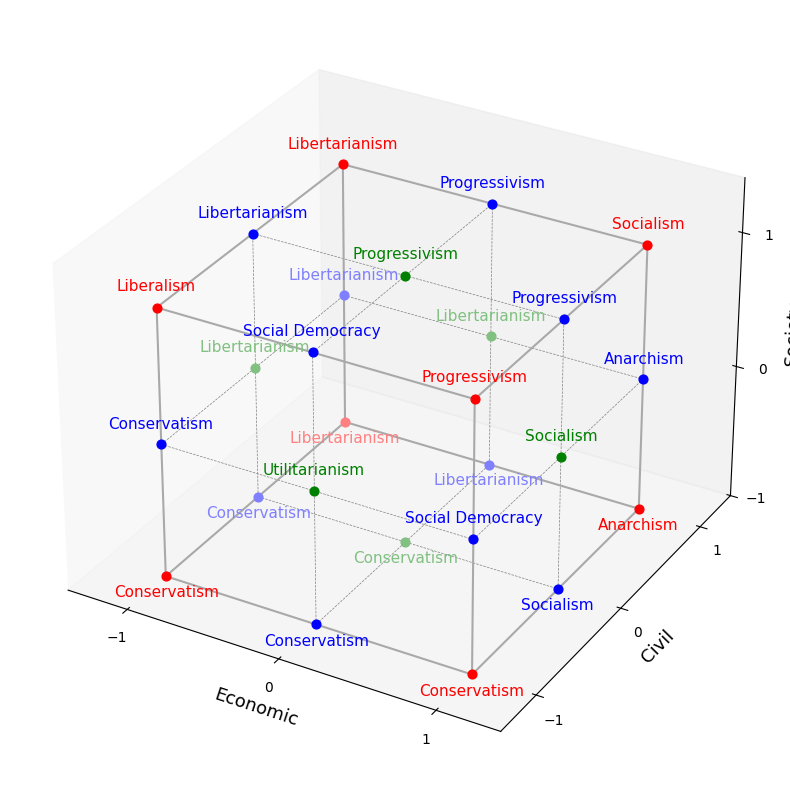

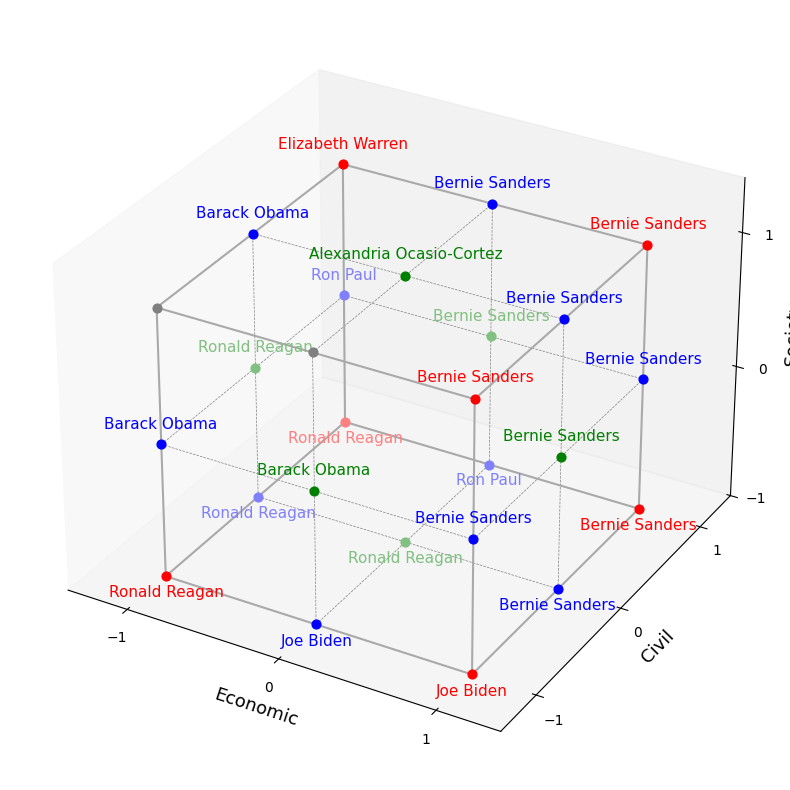

In [31]:
strength = .5
for label, suffix in [("ideology", ""), ("politician_hist_us", "")]:#, ("politician_hist_us", "")
    model_suffix = "" #"_mistral-medium"# if model.model_type == "llama-big" else "_" + model.model_type
    with open(os.path.join(this_base_directory, "outputs", "8values/pol_maps", f"{label}_{str(strength).replace('.', ',')}{model_suffix}{suffix}.json")) as f:
        data = json.load(f)
        if type(data) == list: data = data[0]
        for key, pol in data.items():
            if len(pol) > 40:
                data[key] = "" #removing refusals/incoherently long generations
        plot_cube(data, filename=f"{label}_{str(strength).replace('.', ',')}{model_suffix}{suffix}")

In [135]:
results = {'econ+': 6.714285714285714, 'econ-': 3.2857142857142856, 'econ_baseline': 4.357142857142857, 
'govt+': 6.095238095238095, 'govt-': 4.238095238095238, 'govt_baseline': 4.880952380952381, 
'scty+': 6.523809523809524, 'scty-': 4.0, 'scty_baseline': 4.928571428571429, 
'dipl+': 6.0476190476190474, 'dipl-': 4.142857142857143, 'dipl_baseline': 4.595238095238095}
for key, value in results.copy().items():
    if "baseline" not in key:
        results["delta_" + key] = round(value - results[key[:-1] + "_baseline"], 2)
print(results)

{'econ+': 6.714285714285714, 'econ-': 3.2857142857142856, 'econ_baseline': 4.357142857142857, 'govt+': 6.095238095238095, 'govt-': 4.238095238095238, 'govt_baseline': 4.880952380952381, 'scty+': 6.523809523809524, 'scty-': 4.0, 'scty_baseline': 4.928571428571429, 'dipl+': 6.0476190476190474, 'dipl-': 4.142857142857143, 'dipl_baseline': 4.595238095238095, 'delta_econ+': 2.36, 'delta_econ-': -1.07, 'delta_govt+': 1.21, 'delta_govt-': -0.64, 'delta_scty+': 1.6, 'delta_scty-': -0.93, 'delta_dipl+': 1.45, 'delta_dipl-': -0.45}


using device cuda, 4 GPUs NVIDIA RTX A6000
24
Pearson's r 0.9296749991532263 (p = 0.0) with slope 0.6395346619017944 (ideal 1)
Pearson's r 0.9063529611145025 (p = 0.0) with slope 0.6208028719134101 (ideal 1)
Pearson's r 0.9393423817921807 (p = 0.0) with slope 0.5336171831946885 (ideal 1)
Pearson's r 0.9539719841653396 (p = 0.0) with slope 0.6738337402058643 (ideal 1)
24


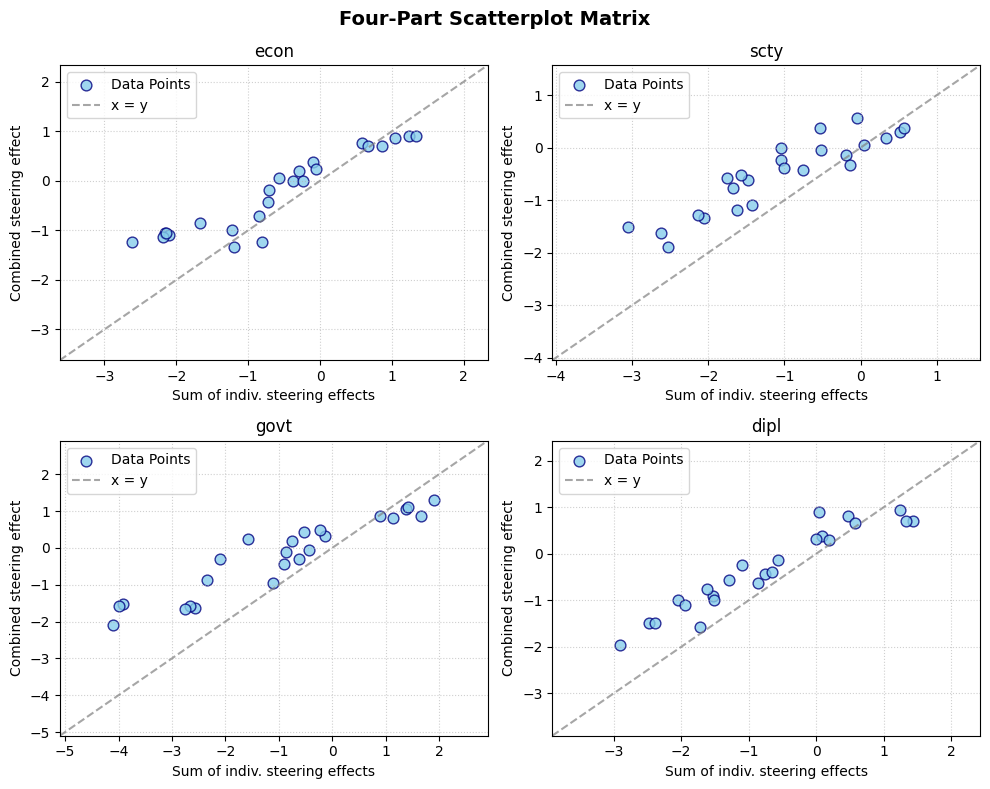

In [2]:
from mapping_pol_space import evaluate_multiaxis_steering, VALUES
pairs_by_axis = evaluate_multiaxis_steering("llama-big")
pairs = [[pairs_by_axis["econ"], pairs_by_axis["govt"]], [pairs_by_axis["scty"], pairs_by_axis["dipl"]]]
print(len(pairs_by_axis["econ"]))
def plot_multiaxis_sum_pairs(pairs: list[list[tuple]]):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    fig.suptitle("Four-Part Scatterplot Matrix", fontsize=14, fontweight="bold")

    for i in range(2):
        for j in range(2):
            ax = axes[i, j]
            data = pairs[i][j]
            
            if data:
                # Unzip tuples into separate x and y lists
                x, y = zip(*data)
                
                # Scatter plot
                ax.scatter(x, y, color="skyblue", edgecolors="navy", s=60, alpha=0.8, label="Data Points")
                
                # Determine plot limits so the x=y line spans the entire visible panel
                min_val = min(min(x), min(y)) - 1
                max_val = max(max(x), max(y)) + 1
                
                # Plot the x = y dashed reference line
                ax.plot([min_val, max_val], [min_val, max_val], color="grey", linestyle="--", alpha=0.7, label="x = y")
                
                # Set equal axis limits to maintain a 1:1 visual aspect ratio for x=y
                ax.set_xlim(min_val, max_val)
                ax.set_ylim(min_val, max_val)
            
            # Formatting
            ax.set_title(list(VALUES.keys())[(2*j)+i])
            ax.set_xlabel("Sum of indiv. steering effects")
            ax.set_ylabel("Combined steering effect")
            ax.grid(True, linestyle=":", alpha=0.6)
            ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()
plot_multiaxis_sum_pairs(pairs)

In [4]:
scores = {
"econ_anno": [4.0, 5.0, 5.5, 6.5, 4.0, 4.0, 3.0, 3.0, 4.0, 2.5, 5.0, 5.5, 5.0, 7.0, 5.0, 3.0, 4.0, 4.0, 4.0, 4.5, 4.0, 5.0, 4.5, 4.0, 5.5, 4.0, 4.0, 2.5, 4.5, 6.0, 5.5, 4.0, 5.5, 6.0, 6.0, 4.0, 3.5, 4.0, 3.0, 3.5, 4.0, 5.0, 5.0, 5.0, 4.0, 2.0, 2.0, 2.0, 2.0, 3.0, 4.0, 4.0, 4.0, 5.0, 5.0, 2.0, 4.0, 4.0, 4.0, 4.0, 6.0, 6.0, 5.0, 4.0, 6.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 6.0, 6.0, 6.0, 6.0, 4.0, 4.0, 4.0, 4.0, 3.0]
,"econ_llm": [7, 7, 6, 7, 6, 4, 4, 1, 4, 4, 6, 6, 6, 7, 6, 4, 4, 4, 4, 6, 7, 7, 6, 5, 7, 4, 4, 5, 6, 6, 6, 7, 6, 7, 7, 4, 1, 4, 2, 4, 6, 7, 6, 7, 6, 3, 2, 4, 4, 2, 6, 6, 6, 7, 7, 4, 4, 4, 4, 4, 7, 7, 6, 6, 7, 4, 4, 4, 4, 6, 6, 7, 7, 7, 7, 4, 4, 4, 4, 4]
,"govt_anno":  [6.5, 2.0, 5.5, 6.0, 7.0, 2.5, 4.0, 6.5, 5.5, 4.0, 7.0, 7.0, 4.5, 5.0, 6.5, 4.0, 4.0, 4.0, 4.0, 3.0, 6.5, 5.5, 5.0, 6.5, 6.0, 2.5, 3.0, 4.0, 6.0, 4.0, 5.5, 5.5, 4.5, 4.5, 6.0, 3.0, 7.0, 3.0, 5.0, 2.5, 7.0, 4.0, 6.0, 6.0, 6.0, 4.0, 4.0, 4.0, 4.0, 4.0, 5.0, 6.0, 7.0, 5.0, 7.0, 3.0, 2.0, 1.0, 2.0, 1.0, 7.0, 6.0, 4.0, 5.0, 6.0, 4.0, 4.0, 4.0, 4.0, 4.0, 5.0, 5.0, 6.0, 5.0, 5.0, 4.0, 4.0, 3.0, 3.0, 2.0]
,"govt_llm": [7, 2, 6, 7, 7, 5, 4, 6, 4, 4, 7, 7, 6, 6, 7, 4, 4, 4, 4, 5, 7, 6, 6, 6, 6, 2, 2, 5, 6, 6, 6, 7, 7, 6, 6, 3, 7, 4, 6, 3, 7, 3, 7, 7, 6, 5, 4, 4, 5, 4, 7, 7, 6, 7, 7, 3, 2, 2, 2, 3, 7, 6, 6, 6, 7, 1, 2, 4, 2, 4, 7, 7, 7, 7, 7, 3, 7, 4, 2, 2]
,"scty_anno": [7.0, 4.5, 7.0, 7.0, 6.0, 4.0, 3.5, 5.0, 4.0, 4.0, 7.0, 7.0, 5.5, 5.5, 5.0, 4.5, 4.0, 4.0, 4.0, 4.0, 7.0, 7.0, 6.0, 6.5, 7.0, 1.5, 1.0, 1.0, 6.5, 3.5, 7.0, 7.0, 6.5, 7.0, 7.0, 4.0, 3.0, 4.0, 4.0, 3.0, 7.0, 6.0, 7.0, 6.0, 6.0, 4.0, 4.0, 4.0, 4.0, 4.0, 5.0, 7.0, 6.0, 7.0, 6.0, 2.0, 3.0, 3.0, 2.0, 2.0, 7.0, 6.0, 5.0, 6.0, 6.0, 1.0, 1.0, 1.0, 1.0, 1.0, 7.0, 7.0, 7.0, 7.0, 7.0, 4.0, 2.0, 2.0, 2.0, 1.0]
,"scty_llm":  [7, 7, 7, 7, 6, 5, 5, 6, 4, 4, 7, 7, 6, 7, 6, 6, 4, 4, 4, 5, 7, 7, 6, 6, 7, 1, 1, 5, 6, 6, 6, 7, 7, 7, 7, 4, 1, 4, 4, 2, 7, 7, 7, 7, 6, 5, 5, 5, 5, 5, 7, 7, 7, 7, 7, 2, 2, 1, 2, 3, 7, 7, 7, 7, 7, 1, 1, 1, 1, 2, 7, 7, 7, 7, 7, 4, 1, 1, 1, 2]
,"dipl_anno": [4.0, 4.0, 4.0, 7.0, 4.0, 4.0, 1.5, 4.0, 4.0, 4.0, 6.5, 4.0, 4.0, 4.0, 4.0, 5.5, 3.0, 4.0, 4.0, 4.0, 4.0, 7.0, 4.0, 4.0, 4.0, 4.0, 2.0, 3.5, 4.0, 4.0, 6.5, 4.0, 7.0, 7.0, 7.0, 1.0, 2.0, 3.5, 3.0, 2.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 3.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 3.0, 3.0, 4.0, 3.0, 4.0, 4.0, 5.0, 5.0, 4.0, 4.0, 4.0, 3.0, 4.0, 4.0, 4.0, 7.0, 4.0, 5.0, 4.0, 6.0, 3.0, 3.0, 1.0, 2.0, 1.0]
,"dipl_llm": [7, 7, 6, 7, 5, 4, 2, 4, 4, 4, 6, 5, 6, 6, 5, 5, 4, 4, 4, 4, 6, 7, 4, 4, 6, 1, 1, 5, 5, 4, 6, 7, 7, 7, 7, 2, 1, 4, 4, 2, 6, 7, 6, 7, 6, 4, 4, 4, 4, 4, 6, 6, 7, 6, 7, 2, 2, 1, 2, 4, 7, 7, 6, 5, 6, 1, 1, 4, 1, 4, 7, 6, 7, 7, 7, 3, 1, 1, 1, 1]
}
all_pos_ixs = []
for i in range(4): all_pos_ixs.extend(list(range(10*i, 10*i+5)) + list(range(40+10*i, 40+10*i+5)))
all_neg_ixs = []
for i in range(4): all_neg_ixs.extend(list(range(10*i+5, 10*i+10)) + list(range(40+10*i+5, 40+10*i+10)))

for i, axis in enumerate(["econ", "govt", "scty", "dipl"]):
    primary_pos_range = list(range(10*i, 10*i+5)) + list(range(40+10*i, 40+10*i+5))
    primary_neg_range = list(range(10*i+5, 10*i+10)) + list(range(40+10*i+5, 40+10*i+10))
    print(primary_pos_range)
    print(primary_neg_range)
    primary_pos = [score for i, score in enumerate(scores[axis + "_anno"]) if i in primary_pos_range]
    primary_neg = [score for i, score in enumerate(scores[axis + "_anno"]) if i in primary_neg_range]
    primary_pos_llm = [score for i, score in enumerate(scores[axis + "_llm"]) if i in primary_pos_range]
    primary_neg_llm = [score for i, score in enumerate(scores[axis + "_llm"]) if i in primary_neg_range]
    sec = [score for i, score in enumerate(scores[axis + "_anno"]) if i in all_pos_ixs and i not in primary_pos_range ]
    sec_neg = [score for i, score in enumerate(scores[axis + "_anno"]) if i in all_neg_ixs and i not in primary_neg_range]
    sec_llm = [score for i, score in enumerate(scores[axis + "_llm"]) if i in all_pos_ixs and i not in primary_pos_range]
    sec_llm_neg = [score for i, score in enumerate(scores[axis + "_llm"]) if i in all_neg_ixs and i not in primary_neg_range]
    
    print(f"{axis}: Average over/underestimation LLM vs. human primary: positive {round(sum(primary_pos_llm)/10 - sum(primary_pos)/10, 2)}, negative: {round(sum(primary_neg_llm)/10 - sum(primary_neg)/10, 2)}")
    print(f"{axis}: Average over/underestimation LLM vs. human secondary: positive {round(sum(sec_llm)/30 - sum(sec)/30, 2)}, negative {round(sum(sec_llm_neg)/30 - sum(sec_neg)/30, 2)}")
    

[0, 1, 2, 3, 4, 40, 41, 42, 43, 44]
[5, 6, 7, 8, 9, 45, 46, 47, 48, 49]
econ: Average over/underestimation LLM vs. human primary: positive 1.7, negative: 0.45
econ: Average over/underestimation LLM vs. human secondary: positive 1.35, negative 0.28
[10, 11, 12, 13, 14, 50, 51, 52, 53, 54]
[15, 16, 17, 18, 19, 55, 56, 57, 58, 59]
govt: Average over/underestimation LLM vs. human primary: positive 0.7, negative: 0.5
govt: Average over/underestimation LLM vs. human secondary: positive 0.78, negative 0.05
[20, 21, 22, 23, 24, 60, 61, 62, 63, 64]
[25, 26, 27, 28, 29, 65, 66, 67, 68, 69]
scty: Average over/underestimation LLM vs. human primary: positive 0.45, negative: 0.65
scty: Average over/underestimation LLM vs. human secondary: positive 0.37, negative 0.13
[30, 31, 32, 33, 34, 70, 71, 72, 73, 74]
[35, 36, 37, 38, 39, 75, 76, 77, 78, 79]
dipl: Average over/underestimation LLM vs. human primary: positive 1.05, negative: -0.15
dipl: Average over/underestimation LLM vs. human secondary: posit